# Conflating Geometries onto a Network

Elastic conflation can adjusts segment geometries to a reference network while preserving their shape and enforcing endpoint constraints imposed by the network.

The following example illustrates how to conflate geometries onto a network using `tracklib`.

## Imports

In [1]:
# Import the tracklib library
import tracklib as tkl

# Import the plotting library
import matplotlib.pyplot as plt

Code running in a no shapely environment


## Loading the Network

(6511250.0, 6511390.0)

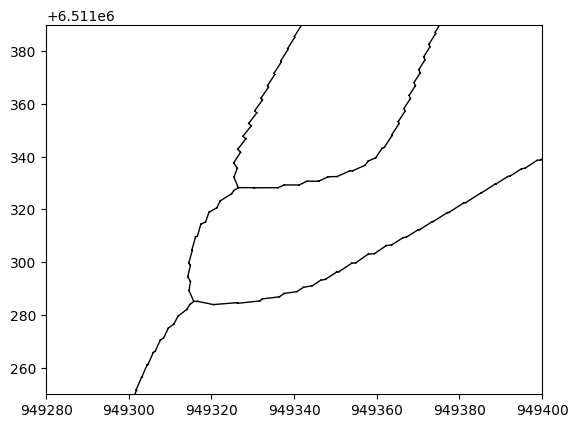

In [2]:
# Then, we can load data
netpath = "../../../data/network/network_before_agg.csv"

fmt = tkl.NetworkFormat({
       "pos_edge_id": 1,
       "pos_source": 2,
       "pos_target": 3,
       "pos_wkt": 0,
       "srid": "ENU",
       "separator": ";",
       "header": 1})

network = tkl.NetworkReader.readFromFile(netpath, fmt, verbose=False)
network.plot('k-', '', 'g-', 'r-', 1, plt)
plt.xlim([949280, 949400])
plt.ylim([6511250, 6511390])

## Loading the Geometries to Be Conflated

(6511250.0, 6511390.0)

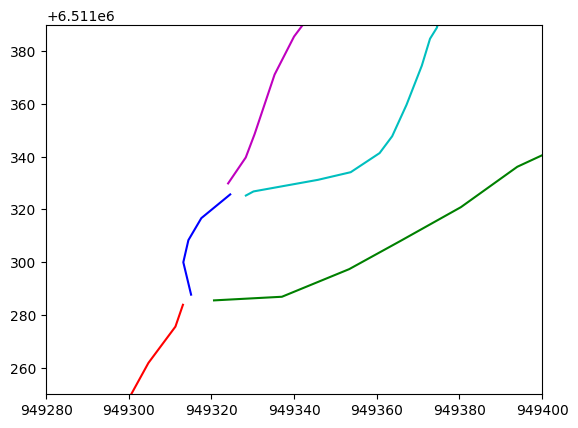

In [3]:
geompath = "../../../data/collection/fusions.csv"

fmt = tkl.TrackFormat({'ext': 'WKT',
                           'srid': 'ENU',
                           'id_wkt': 0,
                       'id_track': 1,
                       'id_T': -1,
                           'separator': ';',
                           'header': 1
                      })

fusions = tkl.TrackReader.readFromFile(geompath, fmt)
fusions.plot()
plt.xlim([949280, 949400])
plt.ylim([6511250, 6511390])

## Performing the Conflation



#593         MED:  0.036 m      RMSE:  0.281 m      MAX:  2.918 m      MATCH:  2.640 m
#596         MED:  0.076 m      RMSE:  0.522 m      MAX:  4.917 m      MATCH:  3.521 m
#542         MED:  2.097 m      RMSE:  2.246 m      MAX:  3.225 m      MATCH:  2.940 m
#543         MED:  0.681 m      RMSE:  1.535 m      MAX:  4.534 m      MATCH:  4.061 m
#550         MED:  0.297 m      RMSE:  0.792 m      MAX:  2.923 m      MATCH:  2.623 m
-----------------------------------------------------------------------------------------
Number of conflated segments :      5       (100.00%)
Total distorsion RMSE        :   0.822 m     (MAX:  4.917 m)


(6511250.0, 6511390.0)

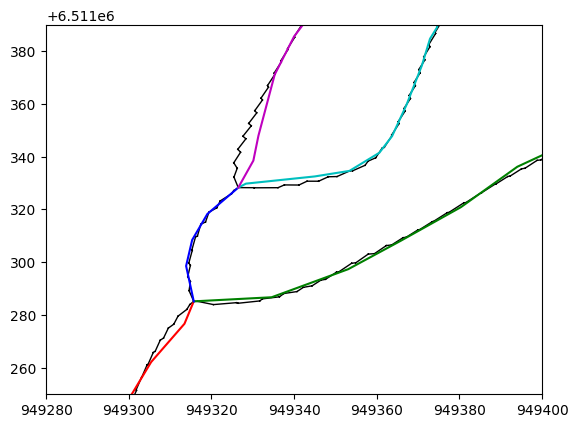

In [4]:
threshold = 20
h         = 20

max_total  = 0
rmse_total = 0
matched    = 0

out = tkl.TrackCollection()

for segment in fusions:
    if segment.tid == -1:
        continue
    
    edge = network.getEdge(segment.tid)
    p1 = edge.source.coord
    p2 = edge.target.coord
        
    h11 = p1.distance2DTo(segment[ 0].position); h12 = p2.distance2DTo(segment[-1].position); h1 = (h11**2+h12**2)**0.5/1.414
    h21 = p1.distance2DTo(segment[-1].position); h22 = p2.distance2DTo(segment[ 0].position); h2 = (h21**2+h22**2)**0.5/1.141
    HMIN = min(h1, h2)
    
    if (h2 < h1):
        ptemp = p1; p1 = p2; p2 = ptemp
        
        
    if (HMIN < threshold):
        
        conflated = tkl.conflate(segment, [p1, p2], [0, -1], h)

        MED = tkl.compare(segment, conflated, mode=tkl.MODE_COMPARISON_POINTWISE, p=1)
        MSE = tkl.compare(segment, conflated, mode=tkl.MODE_COMPARISON_POINTWISE, p=2)
        MAX = tkl.compare(segment, conflated, mode=tkl.MODE_COMPARISON_POINTWISE, p=float('inf'))
        print("#{:6s}      MED: {:6.3f} m      RMSE: {:6.3f} m      MAX: {:6.3f} m      MATCH: {:6.3f} m".format(segment.tid, MED, MSE, MAX, HMIN))
        rmse_total += MSE**2
        max_total = max(max_total, MAX)
        matched += 1
            
    else:
        conflated = segment.copy()
            
    conflated.tid = segment.tid    
    out.addTrack(conflated)
    
if (len(fusions) > 2):
    rmse_total = (rmse_total/len(fusions)-1)**0.5
    print("-----------------------------------------------------------------------------------------")
    print("Number of conflated segments :     ",   matched, "      ({:2.2f}%)".format(matched/len(fusions)*100))
    print("Total distorsion RMSE        :  {:6.3f} m     (MAX: {:6.3f} m)".format(rmse_total, max_total))



network.plot('k-', '', 'g-', 'r-', 1, plt)
out.plot()
plt.xlim([949280, 949400])
plt.ylim([6511250, 6511390])


## For gallery

[]

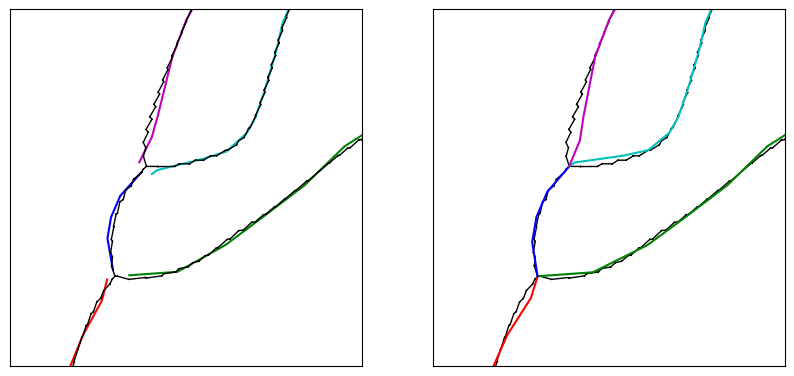

In [5]:
plt.figure(figsize=(10, 3))
plt.subplots_adjust(top=1.3, wspace=0.2, hspace=0.5)

ax1 = plt.subplot2grid((1, 2), (0, 0))
fusions.plot(append=ax1)
network.plot('k-', '', 'g-', 'r-', 1, ax1)
ax1.set_xlim([949280, 949400])
ax1.set_ylim([6511250, 6511390])
ax1.set_xticks([])
ax1.set_yticks([])

ax2 = plt.subplot2grid((1, 2), (0, 1))
network.plot('k-', '', 'g-', 'r-', 1, ax2)
out.plot(append=ax2)
ax2.set_xlim([949280, 949400])
ax2.set_ylim([6511250, 6511390])
ax2.set_xticks([])
ax2.set_yticks([])